In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Load the data
df = pd.read_csv("netflix_titles.csv")   # adjust path if needed

print("Shape:", df.shape)
print("\nFirst 5 rows:")
display(df.head())
print("\nInfo:")
df.info()
print("\nMissing values:")
print(df.isnull().sum())

Shape: (8807, 12)

First 5 rows:


,show_id,type,title,director,cast,country,date_added,release_year,rating,duration,listed_in,description
0,s1,Movie,Dick Johnson Is Dead,Kirsten Johnson,NaN,United States,"September 25, 2021",2020,PG-13,90 min,Documentaries,"As her father nears the end of his life, filmm..."
1,s2,TV Show,Blood & Water,NaN,"Ama Qamata, Khosi Ngema, Gail Mabalane, Thaban...",South Africa,"September 24, 2021",2021,TV-MA,2 Seasons,"International TV Shows, TV Dramas, TV Mysteries","After crossing paths at a party, a Cape Town t..."
2,s3,TV Show,Ganglands,Julien Leclercq,"Sami Bouajila, Tracy Gotoas, Samuel Jouy, Nabi...",NaN,"September 24, 2021",2021,TV-MA,1 Season,"Crime TV Shows, International TV Shows, TV Act...",To protect his family from a powerful drug lor...
3,s4,TV Show,Jailbirds New Orleans,NaN,NaN,NaN,"September 24, 2021",2021,TV-MA,1 Season,"Docuseries, Reality TV","Feuds, flirtations and toilet talk go down amo..."
4,s5,TV Show,Kota Factory,NaN,"Mayur More, Jitendra Kumar, Ranjan Raj, Alam K...",India,"September 24, 2021",2021,TV-MA,2 Seasons,"International TV Shows, Romantic TV Shows, TV ...",In a city of coaching centers known to train I...



Info:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8807 entries, 0 to 8806
Data columns (total 12 columns):
 #   Column        Non-Null Count  Dtype 
---  ------        --------------  ----- 
 0   show_id       8807 non-null   object
 1   type          8807 non-null   object
 2   title         8807 non-null   object
 3   director      6173 non-null   object
 4   cast          7982 non-null   object
 5   country       7976 non-null   object
 6   date_added    8797 non-null   object
 7   release_year  8807 non-null   int64 
 8   rating        8803 non-null   object
 9   duration      8804 non-null   object
 10  listed_in     8807 non-null   object
 11  description   8807 non-null   object
dtypes: int64(1), object(11)
memory usage: 825.8+ KB

Missing values:
show_id            0
type               0
title              0
director        2634
cast             825
country          831
date_added        10
release_year       0
rating             4
duration           3
listed_in         

In [2]:
df_clean = df.copy()

In [3]:
df_clean['director'] = df_clean['director'].fillna('Unknown')
df_clean['cast'] = df_clean['cast'].fillna('Unknown')
df_clean['country'] = df_clean['country'].fillna('Unknown')

In [5]:
df_clean = df_clean.dropna(subset=['date_added', 'rating', 'duration'])
## Drop rows with missing date_added, rating, or duration (very few rows)

In [6]:
df_clean['date_added'] = pd.to_datetime(df_clean['date_added'].str.strip())

In [7]:

# 3. Extract year and month added (useful for trends)
df_clean['year_added'] = df_clean['date_added'].dt.year
df_clean['month_added'] = df_clean['date_added'].dt.month

In [8]:
# 4. Clean duration → create two new columns
# duration looks like "90 min" or "2 Seasons"
df_clean['duration_num'] = df_clean['duration'].str.extract(r'(\d+)').astype(int)
df_clean['duration_type'] = df_clean['duration'].str.extract(r'([a-zA-Z]+)')

In [9]:
# Quick check
print("Shape after cleaning:", df_clean.shape)
print("\nMissing values now:")
print(df_clean.isnull().sum())
print("\nSample of cleaned data:")
display(df_clean[['type', 'title', 'country', 'date_added', 'year_added', 'duration', 'duration_num', 'duration_type']].head(10))

Shape after cleaning: (8790, 16)

Missing values now:
show_id          0
type             0
title            0
director         0
cast             0
country          0
date_added       0
release_year     0
rating           0
duration         0
listed_in        0
description      0
year_added       0
month_added      0
duration_num     0
duration_type    0
dtype: int64

Sample of cleaned data:


,type,title,country,date_added,year_added,duration,duration_num,duration_type
0,Movie,Dick Johnson Is Dead,United States,2021-09-25,2021,90 min,90,min
1,TV Show,Blood & Water,South Africa,2021-09-24,2021,2 Seasons,2,Seasons
2,TV Show,Ganglands,Unknown,2021-09-24,2021,1 Season,1,Season
3,TV Show,Jailbirds New Orleans,Unknown,2021-09-24,2021,1 Season,1,Season
4,TV Show,Kota Factory,India,2021-09-24,2021,2 Seasons,2,Seasons
5,TV Show,Midnight Mass,Unknown,2021-09-24,2021,1 Season,1,Season
6,Movie,My Little Pony: A New Generation,Unknown,2021-09-24,2021,91 min,91,min
7,Movie,Sankofa,"United States, Ghana, Burkina Faso, United Kin...",2021-09-24,2021,125 min,125,min
8,TV Show,The Great British Baking Show,United Kingdom,2021-09-24,2021,9 Seasons,9,Seasons
9,Movie,The Starling,United States,2021-09-24,2021,104 min,104,min


In [10]:
# Set a nice style for all plots
plt.style.use('seaborn-v0_8-whitegrid')
plt.rcParams['figure.figsize'] = (12, 6)
plt.rcParams['font.size'] = 12

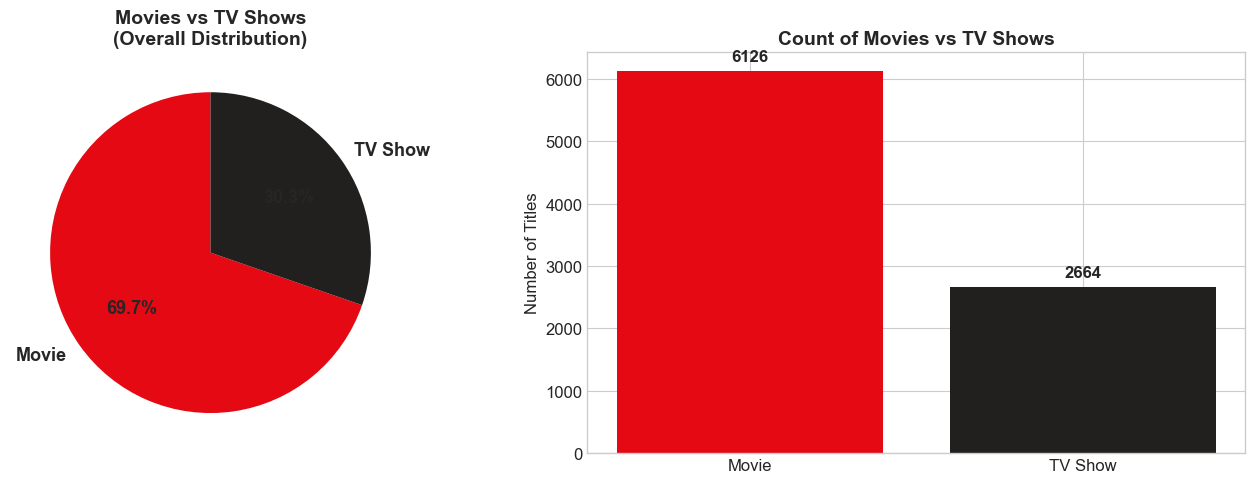

Exact counts:
type
Movie      6126
TV Show    2664
Name: count, dtype: int64

Movies make up 69.7% of the catalog


In [14]:
# ============================================
# 1. Movies vs TV Shows - Overall Distribution
# ============================================
type_counts = df_clean['type'].value_counts()

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Pie chart
axes[0].pie(type_counts, labels=type_counts.index, autopct='%1.1f%%',
            startangle=90, colors=['#E50914', '#221F1F'],
            textprops={'fontsize': 13, 'fontweight': 'bold'})
axes[0].set_title('Movies vs TV Shows\n(Overall Distribution)', fontsize=14, fontweight='bold')

# Bar chart
bars = axes[1].bar(type_counts.index, type_counts.values, color=['#E50914', '#221F1F'])
axes[1].set_title('Count of Movies vs TV Shows', fontsize=14, fontweight='bold')
axes[1].set_ylabel('Number of Titles')
for bar in bars:
    height = bar.get_height()
    axes[1].annotate(f'{int(height)}',
                     xy=(bar.get_x() + bar.get_width() / 2, height),
                     xytext=(0, 5), textcoords="offset points",
                     ha='center', va='bottom', fontweight='bold')

plt.tight_layout()
plt.show()

print("Exact counts:")
print(type_counts)
print(f"\nMovies make up {type_counts['Movie']/len(df_clean)*100:.1f}% of the catalog")

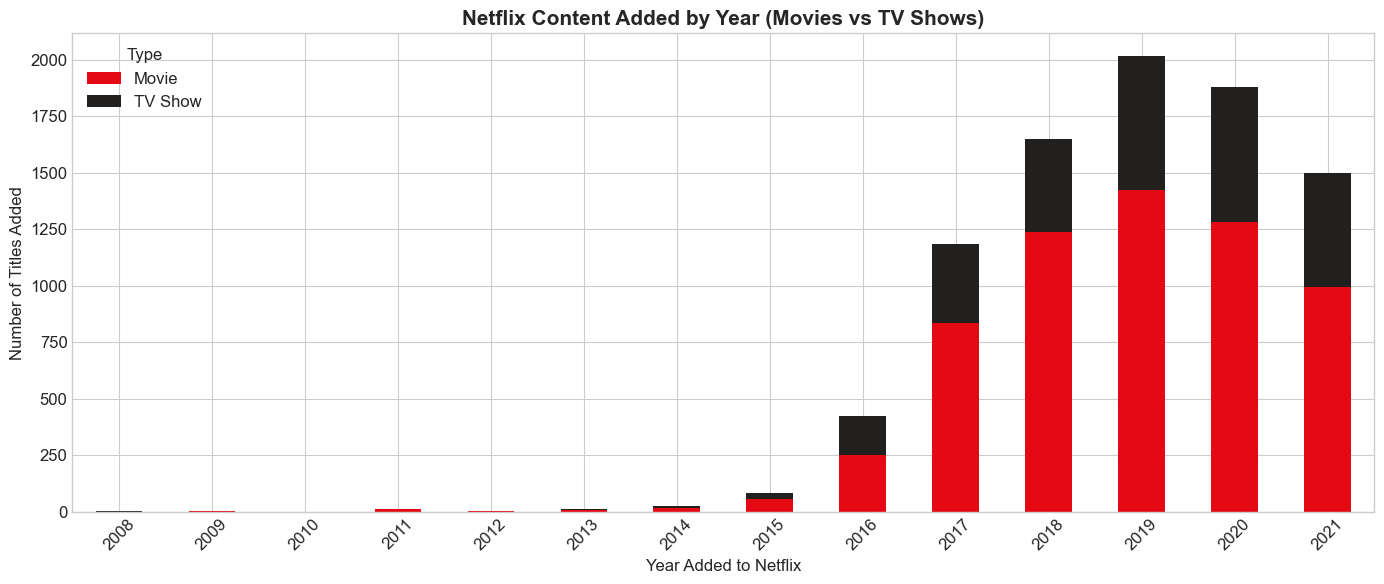


Content added by year:
type        Movie  TV Show
year_added                
2012            3        0
2013            6        5
2014           19        5
2015           56       26
2016          251      175
2017          836      349
2018         1237      411
2019         1424      592
2020         1284      595
2021          993      505


In [15]:
# ============================================
# 2. Content Added Over the Years
# ============================================
content_by_year = df_clean.groupby(['year_added', 'type']).size().unstack(fill_value=0)

fig, ax = plt.subplots(figsize=(14, 6))
content_by_year.plot(kind='bar', stacked=True, ax=ax, color=['#E50914', '#221F1F'])
ax.set_title('Netflix Content Added by Year (Movies vs TV Shows)', fontsize=15, fontweight='bold')
ax.set_xlabel('Year Added to Netflix')
ax.set_ylabel('Number of Titles Added')
ax.legend(title='Type')
ax.tick_params(axis='x', rotation=45)
plt.tight_layout()
plt.show()

print("\nContent added by year:")
print(content_by_year.tail(10))   # last 10 years